# JS09 - Tugas Lab 2: Pencarian Track Terdekat pada Dataset Spotify



## Langkah 0 - Import Library

In [1]:
import pandas as pd
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

## Langkah 1 - Load Dataset



In [2]:
dataset_spotify = r'D:\Data Tugas\SEM 5\ML\asset\songs_with_attributes_and_lyrics.csv'

kolom = ['name', 'artists', 'danceability', 'energy', 'loudness', 'speechiness',
         'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
df = pd.read_csv(dataset_spotify, usecols=kolom)
df.head()

,name,artists,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,!,HELLYEAH,0.415,0.6050,-11.157,0.0575,0.00116,0.838000,0.4710,0.193,100.059
1,!!,Yxngxr1,0.788,0.6480,-9.135,0.3150,0.90000,0.000000,0.1760,0.287,79.998
2,!!! - Interlude,Glowie,0.000,0.0354,-20.151,0.0000,0.90800,0.000000,0.4790,0.000,0.000
3,!!De Repente!!,Rosendo,0.657,0.8820,-6.340,0.0385,0.00740,0.000013,0.0474,0.939,123.588
4,!!De Repente!!,Rosendo,0.659,0.8930,-8.531,0.0411,0.09220,0.000019,0.0534,0.951,123.600


In [3]:
df.info()

print('\nJumlah missing value per kolom:')
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 955320 entries, 0 to 955319
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   name              955309 non-null  str    
 1   artists           955315 non-null  str    
 2   danceability      955320 non-null  float64
 3   energy            955320 non-null  float64
 4   loudness          955320 non-null  float64
 5   speechiness       955320 non-null  float64
 6   acousticness      955320 non-null  float64
 7   instrumentalness  955320 non-null  float64
 8   liveness          955320 non-null  float64
 9   valence           955320 non-null  float64
 10  tempo             955320 non-null  float64
dtypes: float64(9), str(2)
memory usage: 80.2 MB

Jumlah missing value per kolom:
name                11
artists              5
danceability         0
energy               0
loudness             0
speechiness          0
acousticness         0
instrumentalness     0
liveness  

## Langkah 2 - Pemilihan Fitur Numerik dan Standardisasi

Fitur numerik yang digunakan adalah 9 atribut audio yang menggambarkan karakter musik: `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, dan `tempo`.



In [4]:
features = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
X = df[features].values

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k = 10  # jumlah nearest neighbors

print('Shape data asli   :', X.shape)
print('Shape data scaled :', X_scaled.shape)
print('\nStatistik fitur sebelum scaling:')
print(df[features].describe().loc[['mean', 'std']].round(3))
print('\nStatistik fitur sesudah scaling:')
print(pd.DataFrame(X_scaled, columns=features).describe().loc[['mean', 'std']].round(3))

Shape data asli   : (955320, 9)
Shape data scaled : (955320, 9)

Statistik fitur sebelum scaling:


      danceability  energy  loudness  speechiness  acousticness  \
mean         0.551   0.652    -7.834        0.084         0.283   
std          0.170   0.239     3.792        0.093         0.312   

      instrumentalness  liveness  valence    tempo  
mean             0.082     0.220    0.488  122.226  
std              0.213     0.196    0.251   29.536  

Statistik fitur sesudah scaling:


      danceability  energy  loudness  speechiness  acousticness  \
mean          -0.0    -0.0       0.0          0.0          -0.0   
std            1.0     1.0       1.0          1.0           1.0   

      instrumentalness  liveness  valence  tempo  
mean              -0.0      -0.0     -0.0   -0.0  
std                1.0       1.0      1.0    1.0  


## Langkah 3 - Exact NN (Baseline)

Exact NN dihitung dengan `NearestNeighbors` dari scikit-learn (*brute force*) sebagai acuan (ground truth). Query yang digunakan adalah satu track acak dari dataset; karena query berasal dari dataset itu sendiri, tetangga pertama adalah track itu sendiri sehingga diabaikan (*exclude self*), lalu diambil 10 tetangga terdekat.



In [5]:
np.random.seed(42)

# Track query (acak dari dataset)
idx_query = np.random.randint(0, len(df))
query_track = df.iloc[idx_query]
print(f"Query track : {query_track['name']} — {query_track['artists']}")
print(f"Index       : {idx_query}")

# 100 query acak untuk pengukuran waktu
idx_queries = np.random.choice(len(df), size=100, replace=False)
Q = X_scaled[idx_queries].astype(np.float32)

X_float = X_scaled.astype(np.float32)

Query track : Caminho das Pedras — Quinteto em Branco e Preto
Index       : 121958


In [6]:
# Build model Exact NN
start = time.time()
nn = NearestNeighbors(n_neighbors=k + 1, algorithm='brute', metric='euclidean')
nn.fit(X_float)
build_exact = time.time() - start

# Ukur waktu query (100 query)
start = time.time()
dist_exact, idx_exact_all = nn.kneighbors(Q)
query_exact = (time.time() - start) * 1000 / len(Q)  # ms/query

# Ground truth (10 tetangga terdekat, exclude track itu sendiri)
def drop_self(idxs, dists, self_idx):
    keep = [i for i, j in enumerate(idxs) if j != self_idx]
    return idxs[keep], (dists[keep] if dists is not None else None)

gt_idx, gt_dist = drop_self(idx_exact_all[0], dist_exact[0], idx_query)
gt_idx = gt_idx[:k]

print(f"Build time : {build_exact:.4f} s")
print(f"Query time : {query_exact:.4f} ms/query")

hasil_exact = df.iloc[gt_idx][['name', 'artists']].reset_index(drop=True)
hasil_exact['distance'] = gt_dist[:k]
hasil_exact.index += 1
hasil_exact

Build time : 0.0347 s
Query time : 2.3172 ms/query


,name,artists,distance
1,I Stand Redeemed,Legacy Five,0.000000
2,I Stand Redeemed,Legacy Five,0.000000
3,Even Though My Heart Breaks,FLY TO THE SKY,0.305065
4,Si tú me miras,Alejandro Sanz,0.337466
5,Si tú me miras,Alejandro Sanz,0.337466
6,Want Me Around,Lukas Nelson and Promise of the Real,0.344149
7,More Than Anyone,Gavin DeGraw,0.353192
8,More Than Anyone,Gavin DeGraw,0.353192
9,Far Away,Sharon Van Etten,0.376516
10,"Hanggang Saan, Hanggang Kailan",Ogie Alcasid,0.404341


## Langkah 4 - ANNOY

Index ANNOY dibangun dengan 10 tree dan metrik Euclidean pada data yang telah distandarisasi.

In [7]:
f = len(features)
annoy_index = AnnoyIndex(f, 'euclidean')

start = time.time()
for i, v in enumerate(X_float):
    annoy_index.add_item(i, v)
annoy_index.build(10)  # 10 trees
build_annoy = time.time() - start

start = time.time()
pred_annoy = [annoy_index.get_nns_by_vector(q, k + 1) for q in Q]
query_annoy = (time.time() - start) * 1000 / len(Q)  # ms/query

idx_annoy, _ = drop_self(np.array(pred_annoy[0]), None, idx_query)
idx_annoy = idx_annoy[:k]

print(f"Build time : {build_annoy:.4f} s")
print(f"Query time : {query_annoy:.4f} ms/query")

hasil_annoy = df.iloc[idx_annoy][['name', 'artists']].reset_index(drop=True)
hasil_annoy.index += 1
hasil_annoy

Build time : 7.6739 s
Query time : 0.0781 ms/query


,name,artists
1,I Stand Redeemed,Legacy Five
2,I Stand Redeemed,Legacy Five
3,Even Though My Heart Breaks,FLY TO THE SKY
4,Si tú me miras,Alejandro Sanz
5,Si tú me miras,Alejandro Sanz
6,Want Me Around,Lukas Nelson and Promise of the Real
7,More Than Anyone,Gavin DeGraw
8,More Than Anyone,Gavin DeGraw
9,Far Away,Sharon Van Etten
10,"Hanggang Saan, Hanggang Kailan",Ogie Alcasid


## Langkah 5 - FAISS (IVF)

FAISS digunakan dalam varian **IndexIVFFlat** (inverted file) yaitu metode ANN FAISS: data dikelompokkan ke dalam 256 *cluster* (nlist) dan pencarian hanya dilakukan pada 10 cluster terdekat (`nprobe = 10`).

In [8]:
nlist = 256   # jumlah cluster (inverted list)
nprobe = 10   # jumlah cluster yang dicari

quantizer = faiss.IndexFlatL2(f)
faiss_index = faiss.IndexIVFFlat(quantizer, f, nlist, faiss.METRIC_L2)

start = time.time()
faiss_index.train(X_float)  # training centroid
faiss_index.add(X_float)
build_faiss = time.time() - start

faiss_index.nprobe = nprobe

start = time.time()
_, pred_faiss = faiss_index.search(Q, k + 1)
query_faiss = (time.time() - start) * 1000 / len(Q)  # ms/query

idx_faiss, _ = drop_self(pred_faiss[0], None, idx_query)
idx_faiss = idx_faiss[:k]

print(f"Build time : {build_faiss:.4f} s")
print(f"Query time : {query_faiss:.4f} ms/query")

hasil_faiss = df.iloc[idx_faiss][['name', 'artists']].reset_index(drop=True)
hasil_faiss.index += 1
hasil_faiss

Build time : 1.6047 s
Query time : 0.2436 ms/query


,name,artists
1,I Stand Redeemed,Legacy Five
2,I Stand Redeemed,Legacy Five
3,Even Though My Heart Breaks,FLY TO THE SKY
4,Si tú me miras,Alejandro Sanz
5,Si tú me miras,Alejandro Sanz
6,Want Me Around,Lukas Nelson and Promise of the Real
7,More Than Anyone,Gavin DeGraw
8,More Than Anyone,Gavin DeGraw
9,Far Away,Sharon Van Etten
10,"Hanggang Saan, Hanggang Kailan",Ogie Alcasid


## Langkah 6 - HNSW (hnswlib)

Index HNSW dibangun dengan parameter `M = 16` dan `ef_construction = 200`; saat pencarian digunakan `ef = 50` sebagai *trade-off* antara kecepatan dan akurasi.

In [9]:
hnsw_index = hnswlib.Index(space='l2', dim=f)

start = time.time()
hnsw_index.init_index(max_elements=len(X_float), ef_construction=200, M=16)
hnsw_index.add_items(X_float)
build_hnsw = time.time() - start

hnsw_index.set_ef(50)

start = time.time()
pred_hnsw, _ = hnsw_index.knn_query(Q, k=k + 1)
query_hnsw = (time.time() - start) * 1000 / len(Q)  # ms/query

idx_hnsw, _ = drop_self(pred_hnsw[0], None, idx_query)
idx_hnsw = idx_hnsw[:k]

print(f"Build time : {build_hnsw:.4f} s")
print(f"Query time : {query_hnsw:.4f} ms/query")

hasil_hnsw = df.iloc[idx_hnsw][['name', 'artists']].reset_index(drop=True)
hasil_hnsw.index += 1
hasil_hnsw

Build time : 78.9594 s
Query time : 0.1367 ms/query


,name,artists
1,I Stand Redeemed,Legacy Five
2,I Stand Redeemed,Legacy Five
3,Even Though My Heart Breaks,FLY TO THE SKY
4,Si tú me miras,Alejandro Sanz
5,Si tú me miras,Alejandro Sanz
6,Want Me Around,Lukas Nelson and Promise of the Real
7,More Than Anyone,Gavin DeGraw
8,More Than Anyone,Gavin DeGraw
9,Far Away,Sharon Van Etten
10,"Hanggang Saan, Hanggang Kailan",Ogie Alcasid


## Langkah 7 - Perbandingan Hasil Pencarian Track Terdekat

Perbandingan 10 track terdekat yang ditemukan setiap metode untuk track query pada Langkah 3, beserta jumlah irisan (*overlap*) terhadap hasil exact NN.

In [10]:
def ringkas(idxs):
    return [f"{r['name']} — {r['artists']}"[:45]
            for _, r in df.iloc[idxs][['name', 'artists']].iterrows()]

perbandingan = pd.DataFrame({
    'Exact NN (sklearn)': ringkas(gt_idx),
    'ANNOY': ringkas(idx_annoy),
    'FAISS (IVF)': ringkas(idx_faiss),
    'HNSW': ringkas(idx_hnsw),
})
perbandingan.index += 1

overlap = {
    'ANNOY': len(set(idx_annoy) & set(gt_idx)),
    'FAISS (IVF)': len(set(idx_faiss) & set(gt_idx)),
    'HNSW': len(set(idx_hnsw) & set(gt_idx)),
}
print('Irisan top-10 terhadap Exact NN:', overlap, 'dari', k)
perbandingan

Irisan top-10 terhadap Exact NN: {'ANNOY': 10, 'FAISS (IVF)': 10, 'HNSW': 10} dari 10


,Exact NN (sklearn),ANNOY,FAISS (IVF),HNSW
1,I Stand Redeemed — Legacy Five,I Stand Redeemed — Legacy Five,I Stand Redeemed — Legacy Five,I Stand Redeemed — Legacy Five
2,I Stand Redeemed — Legacy Five,I Stand Redeemed — Legacy Five,I Stand Redeemed — Legacy Five,I Stand Redeemed — Legacy Five
3,Even Though My Heart Breaks — FLY TO THE SKY,Even Though My Heart Breaks — FLY TO THE SKY,Even Though My Heart Breaks — FLY TO THE SKY,Even Though My Heart Breaks — FLY TO THE SKY
4,Si tú me miras — Alejandro Sanz,Si tú me miras — Alejandro Sanz,Si tú me miras — Alejandro Sanz,Si tú me miras — Alejandro Sanz
5,Si tú me miras — Alejandro Sanz,Si tú me miras — Alejandro Sanz,Si tú me miras — Alejandro Sanz,Si tú me miras — Alejandro Sanz
6,Want Me Around — Lukas Nelson and Promise of,Want Me Around — Lukas Nelson and Promise of,Want Me Around — Lukas Nelson and Promise of,Want Me Around — Lukas Nelson and Promise of
7,More Than Anyone — Gavin DeGraw,More Than Anyone — Gavin DeGraw,More Than Anyone — Gavin DeGraw,More Than Anyone — Gavin DeGraw
8,More Than Anyone — Gavin DeGraw,More Than Anyone — Gavin DeGraw,More Than Anyone — Gavin DeGraw,More Than Anyone — Gavin DeGraw
9,Far Away — Sharon Van Etten,Far Away — Sharon Van Etten,Far Away — Sharon Van Etten,Far Away — Sharon Van Etten
10,"Hanggang Saan, Hanggang Kailan — Ogie Alcasid","Hanggang Saan, Hanggang Kailan — Ogie Alcasid","Hanggang Saan, Hanggang Kailan — Ogie Alcasid","Hanggang Saan, Hanggang Kailan — Ogie Alcasid"


### Analisis Pencarian Track Terdekat

Untuk track query **"Caminho das Pedras" — Quinteto em Branco e Preto** (instrumental/vokal Brazil), hasil pencarian sangat meyakinkan: **ketiga metode ANN menemukan 10 dari 10 track yang sama persis dengan exact NN**.

Hasil exact NN menunjukkan tetangga terdekat yang masuk akal secara musikal: *I Stand Redeemed — Legacy Five*, *Even Though My Heart Breaks — FLY TO THE SKY*, *Si tú me miras — Alejandro Sanz*, *Want Me Around — Lukas Nelson and Promise of the Real*, hingga *Far Away — Sharon Van Etten* — track-track dengan karakter vokal dan instrumen yang mirip berdasarkan 9 fitur audio yang distandarisasi.

Hal ini menunjukkan bahwa pada dataset riil, struktur indeks ANNOY, FAISS IVF, dan HNSW mampu mereplikasi hasil exact NN dengan sangat baik untuk query tunggal.

## Langkah 8 - Perbandingan Performansi

Performansi diukur pada 100 query acak dengan `k = 10`: **build time** (waktu membangun indeks), **query time** (rata-rata per query), dan **recall@10** terhadap ground truth exact NN yang dihitung dengan FAISS `IndexFlatL2`.

In [11]:
# Ground truth untuk 100 query menggunakan FAISS Flat (exact)
flat = faiss.IndexFlatL2(f)
flat.add(X_float)
_, gt_all = flat.search(Q, k + 1)

def recall_topk(pred_list, self_ids):
    total = 0
    for p, s, g in zip(pred_list, self_ids, gt_all):
        p = [j for j in p if j != s][:k]
        g = [j for j in g if j != s][:k]
        total += len(set(p) & set(g)) / k
    return total / len(pred_list)

ringkasan = pd.DataFrame({
    'Metode': ['Exact NN (sklearn)', 'ANNOY', 'FAISS (IVF)', 'HNSW'],
    'Build Time (s)': [build_exact, build_annoy, build_faiss, build_hnsw],
    'Query Time (ms/query)': [query_exact, query_annoy, query_faiss, query_hnsw],
    'Recall@10': [1.0,
                  recall_topk(pred_annoy, idx_queries),
                  recall_topk(pred_faiss, idx_queries),
                  recall_topk(pred_hnsw, idx_queries)],
})
ringkasan.round(4)

,Metode,Build Time (s),Query Time (ms/query),Recall@10
0,Exact NN (sklearn),0.0347,2.3172,1.000
1,ANNOY,7.6739,0.0781,0.813
2,FAISS (IVF),1.6047,0.2436,0.998
3,HNSW,78.9594,0.1367,0.990


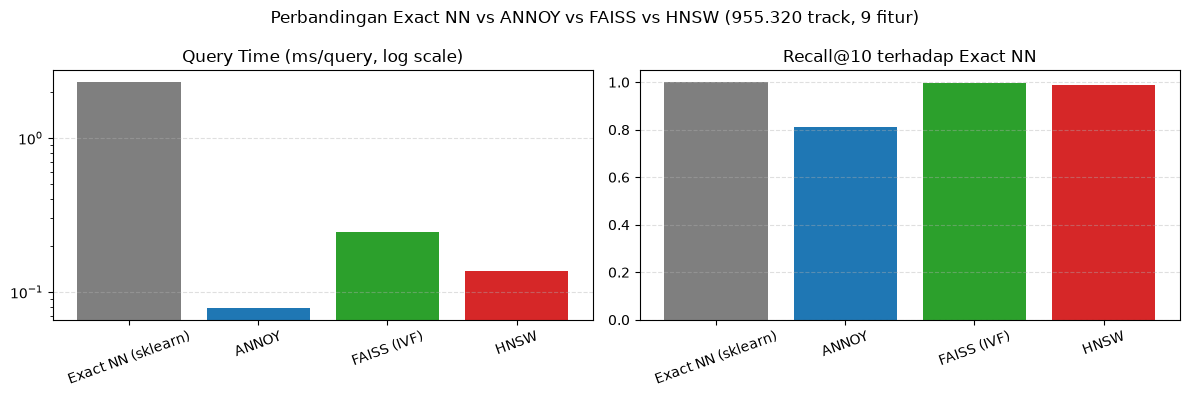

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

warna = ['tab:gray', 'tab:blue', 'tab:green', 'tab:red']
axes[0].bar(ringkasan['Metode'], ringkasan['Query Time (ms/query)'], color=warna)
axes[0].set_yscale('log')
axes[0].set_title('Query Time (ms/query, log scale)')
axes[0].tick_params(axis='x', rotation=20)
axes[0].grid(True, axis='y', ls='--', alpha=0.4)

axes[1].bar(ringkasan['Metode'], ringkasan['Recall@10'], color=warna)
axes[1].set_ylim(0, 1.05)
axes[1].set_title('Recall@10 terhadap Exact NN')
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(True, axis='y', ls='--', alpha=0.4)

plt.suptitle('Perbandingan Exact NN vs ANNOY vs FAISS vs HNSW (955.320 track, 9 fitur)')
plt.tight_layout()
plt.show()